# 자연어 처리 5일차 (1) — RNN 의 한계 · seq2seq 의 고정 길이 문맥 벡터 → 어텐션이 필요한 이유

교재 `자연어처리` 교재v1 **p.79~89** (BPTT 연쇄 법칙 · 기울기 소멸 · 장기 의존성 · 병렬 처리의 한계 · RNN 분류 모델 코드 · seq2seq · Transformer 등장 배경 · 구조) 를 직접 실험해 본 노트입니다.

- self-attention 을 손으로 계산하는 실습(필기 `nlp_실습8`, 교재 p.90~96)은 [`self_attention_scratch.ipynb`](./self_attention_scratch.ipynb) 에 있습니다.
- IMDB RNN 학습 · BPTT 기울기 측정은 [Day 042](../../2026-11-06/lecture/imdb_rnn_sentiment.ipynb) 에서 했습니다.
- 교재에서 고친 부분은 **📝 고친 부분** 으로 적었습니다. **애니메이션(GIF)** 은 [`images/`](./images/) 폴더에 있습니다.

## 0. 설치 · 실행 방법

| 패키지 | 이 노트에서 쓰는 것 | 설치 |
|---|---|---|
| `torch` | RNN · GRU · 기울기 계산 · seq2seq 학습 | Colab 기본 포함 · 로컬은 `pip install torch` |
| `numpy` · `matplotlib` | 계산 · 그래프 | Colab 기본 포함 |

**실행 순서** : 맨 위부터 **[런타임] → [모두 실행]**. 데이터는 코드가 직접 만든다(숫자 뒤집기 과제) — 받을 파일 없음.
**시간** : CPU 로 약 4분(§3 seq2seq 8번 학습이 대부분 · 이 노트 실행 기준). GPU 는 필요 없다.

In [1]:
# ① 설치 (로컬에서 처음 한 번 — Colab 은 기본 포함)
# !pip install -q torch numpy matplotlib

In [2]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
# Colab(리눅스) : !apt-get install -y fonts-nanum 후 런타임 재시작 → plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

In [3]:
import time
import numpy as np
import torch
import torch.nn as nn
_ = torch.manual_seed(0)

## 1. 기울기 소멸 — 무엇이 곱해지나 (교재 p.80~82)

$$\frac{\partial L}{\partial W_x(t=1)} = \frac{\partial L}{\partial h_T}\times\frac{\partial h_T}{\partial h_{T-1}}\times\cdots\times\frac{\partial h_2}{\partial h_1}\times\frac{\partial h_1}{\partial W_x}, \qquad
\frac{\partial h_k}{\partial h_{k-1}} = \underbrace{\mathrm{diag}(1-h_k^2)}_{\tanh'\,\le 1}\;W_h$$

한 칸 거슬러 갈 때마다 **tanh 의 미분값과 $W_h$ 를 함께** 곱한다. 그래서 $W_h$ 의 크기에 따라 결과가 달라진다.

W_h × 0.5 : 10칸 앞 1.0e-03 · 30칸 앞 1.1e-10 · 59칸 앞 9.2e-21
W_h × 1.0 : 10칸 앞 4.7e-01 · 30칸 앞 1.2e-02 · 59칸 앞 1.7e-05
W_h × 3.0 : 10칸 앞 1.8e+01 · 30칸 앞 1.8e+03 · 59칸 앞 1.0e+05


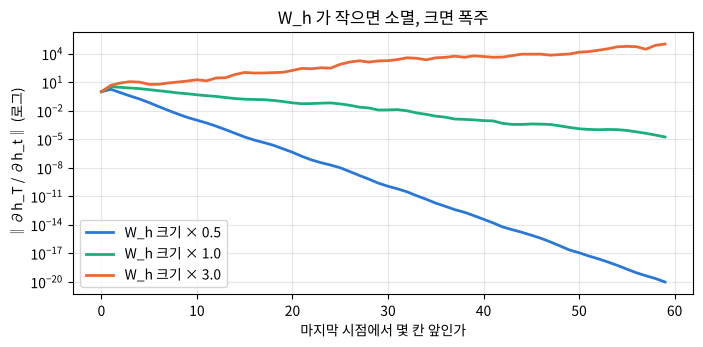

In [4]:
def grad_by_step(scale, T=60, H=16, seed=0):
    """W_h 크기(scale)를 바꿔 가며 ‖∂h_T/∂h_t‖ 를 t = T … 1 로 잰다"""
    g = torch.Generator().manual_seed(seed)
    Wh = torch.randn(H, H, generator=g) / H ** 0.5 * scale      # scale 1 ≈ 크기 1
    Wx = torch.randn(8, H, generator=g) * 0.1
    xs = torch.randn(T, 8, generator=g)
    h = torch.zeros(H); hs = []
    for t in range(T):
        h = torch.tanh(h @ Wh + xs[t] @ Wx)
        hs.append(h)
    J = torch.eye(H); norms = [1.0]
    for t in range(T - 1, 0, -1):                                # 거꾸로 : ∂h_t/∂h_{t-1} 를 곱해 간다
        J = J @ (torch.diag(1 - hs[t] ** 2) @ Wh.T)
        norms.append(J.norm().item())
    return np.array(norms)                                       # [0] = 마지막 시점, [k] = k 칸 앞

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 3.4))
for s, c in [(0.5, '#2a78d6'), (1.0, '#1baf7a'), (3.0, '#eb6834')]:
    n = grad_by_step(s)
    plt.semilogy(n, color=c, lw=2, label=f'W_h 크기 × {s}')
    print(f'W_h × {s} : 10칸 앞 {n[10]:.1e} · 30칸 앞 {n[30]:.1e} · 59칸 앞 {n[59]:.1e}')
plt.xlabel('마지막 시점에서 몇 칸 앞인가'); plt.ylabel('‖∂h_T / ∂h_t‖ (로그)'); plt.legend(); plt.grid(alpha=0.3)
plt.title('W_h 가 작으면 소멸, 크면 폭주'); plt.show()

In [5]:
# tanh 포화가 없다면(선형 RNN) W_h 가 크면 기울기가 '폭주' 한다
H = 16
g = torch.Generator().manual_seed(0)
base = torch.randn(H, H, generator=g) / H ** 0.5
for s in [0.5, 1.0, 1.5]:
    W = base * s
    J = torch.linalg.matrix_power(W.T, 30)
    print(f'선형 RNN · W_h × {s} : 30칸 거슬러 간 기울기 크기 {J.norm().item():.1e}')

선형 RNN · W_h × 0.5 : 30칸 거슬러 간 기울기 크기 1.9e-09
선형 RNN · W_h × 1.0 : 30칸 거슬러 간 기울기 크기 2.1e+00
선형 RNN · W_h × 1.5 : 30칸 거슬러 간 기울기 크기 4.0e+05


> **📝 고친 부분 (교재 p.81 'tanh 미분값이 1 이하이므로 곱할수록 0 으로 수렴')**
> - 한 칸마다 곱해지는 것은 tanh 미분값만이 아니라 **tanh 미분값 × $W_h$** 다(위 식). $W_h$ 가 작으면 소멸이 빨라지고, 크면 기울기가 커지는 **기울기 폭주(exploding)** 도 생긴다 — 그래서 RNN 학습에는 `clip_grad_norm_` 을 함께 쓴다
> - tanh 로 은닉 상태가 ±1 에 붙으면(포화) 미분값이 0 에 가까워져 소멸 쪽으로 당기지만, $W_h$ 가 충분히 크면 그래도 기울기가 커진다 — 위 주황선(× 3.0)이 60칸 동안 계속 커진다
> - 오타 `0으로 수련` → **수렴**

## 2. 병렬 처리의 한계 (교재 p.83)

RNN 은 $h_{t-1}$ 이 있어야 $h_t$ 를 계산할 수 있어 **시점 수만큼 차례로** 돌아야 한다. 어텐션은 문장 전체를 **행렬 곱 한 번**으로 처리한다.

In [6]:
B, T, D = 32, 256, 64
x = torch.randn(B, T, D)
rnn_cell = nn.RNNCell(D, D)

def rnn_loop(x):
    h = torch.zeros(B, D)
    for t in range(T):                         # 시점마다 하나씩 (앞 결과가 있어야 다음 계산)
        h = rnn_cell(x[:, t], h)
    return h

Wq, Wk, Wv = (torch.randn(D, D) / D ** 0.5 for _ in range(3))
def attention_once(x):
    q, k, v = x @ Wq, x @ Wk, x @ Wv           # 모든 시점을 한 번에
    w = torch.softmax(q @ k.transpose(1, 2) / D ** 0.5, dim=-1)
    return w @ v

with torch.no_grad():
    for f, name in [(rnn_loop, 'RNN (256번 순서대로)'), (attention_once, 'self-attention (행렬 곱 한 번)')]:
        f(x); t0 = time.perf_counter()
        for _ in range(5): f(x)
        print(f'{name:30s} {(time.perf_counter() - t0) / 5 * 1000:7.1f} ms')

RNN (256번 순서대로)                    4.3 ms
self-attention (행렬 곱 한 번)         12.8 ms


- 시간은 실행 환경마다 다르다 — 코어가 2개뿐인 CPU 에서는 이 크기의 RNN 루프가 오히려 빠를 수도 있다(위 결과). 어텐션은 $T \times T$ 점수(길이 256 이면 65,536칸)를 계산하므로 **계산량 자체는 더 많다**.
- 핵심 차이는 **기다려야 하는 단계 수** — RNN 은 256번을 앞 결과가 나올 때까지 차례로, 어텐션은 행렬 곱 몇 번을 한꺼번에. 코어가 수천 개인 GPU 에서는 한꺼번에 펼칠 수 있는 쪽이 크게 유리하고, 학습(BPTT)도 같은 이유로 RNN 이 느리다.
- 대신 어텐션은 점수 행렬 때문에 **문장 길이의 제곱**만큼 메모리를 쓴다.

> **📝 고친 부분 (교재 p.83 '병렬 처리 불가')** 정확히는 **한 문장 안의 시점끼리** 병렬이 안 된다. 여러 문장(배치)은 RNN 도 한꺼번에 계산한다(위 코드의 `B = 32`).

## 3. seq2seq — 문장 전체를 '고정 크기' 문맥 벡터 하나로 (교재 p.87)

인코더가 입력을 다 읽은 **마지막 은닉 상태 하나**(문맥 벡터)만 디코더에 넘긴다. 길이가 길어지면 이 한 벡터에 다 담을 수 있을까?

**과제** : 숫자 열 뒤집기 `3 1 4 1 5` → `5 1 4 1 3` (길이 5 · 10 · 20 · 30). 같은 GRU 인코더 · 디코더에
- **문맥 벡터만** 쓰는 기본 seq2seq
- 디코더가 매 단계 인코더의 **모든 시점을 다시 보는** 어텐션(내적 점수 → softmax → 가중합)

을 붙여 비교한다.

In [7]:
V, SOS, HID = 10, 10, 64                 # 숫자 0~9, 시작 토큰 10

def make_batch(n, L):
    x = torch.randint(0, V, (n, L))
    return x, x.flip(1)                  # 정답 = 뒤집은 열

class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(V, 32)
        self.gru = nn.GRU(32, HID, batch_first=True)
    def forward(self, x):
        return self.gru(self.emb(x))     # outputs (n, L, HID) · h (1, n, HID) = 문맥 벡터

class Decoder(nn.Module):
    def __init__(self, use_attention):
        super().__init__()
        self.att = use_attention
        self.emb = nn.Embedding(V + 1, 32)
        self.gru = nn.GRU(32 + (HID if use_attention else 0), HID, batch_first=True)
        self.out = nn.Linear(HID * (2 if use_attention else 1), V)
    def step(self, y, h, enc_out):
        e = self.emb(y).unsqueeze(1)                                         # (n, 1, 32)
        if not self.att:
            o, h = self.gru(e, h)
            return self.out(o.squeeze(1)), h, None
        score = (enc_out @ h[-1].unsqueeze(2)).squeeze(2)                   # (n, L) : 인코더 각 시점과 내적
        w = torch.softmax(score, dim=1)                                      # 어텐션 가중치
        ctx = (w.unsqueeze(2) * enc_out).sum(1, keepdim=True)                # 가중합 (n, 1, HID)
        o, h = self.gru(torch.cat([e, ctx], 2), h)
        return self.out(torch.cat([o.squeeze(1), ctx.squeeze(1)], 1)), h, w

def train_eval(L, use_attention, steps=1500, seed=0):
    torch.manual_seed(seed)
    enc, dec = Encoder(), Decoder(use_attention)
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), lr=3e-3)
    loss_fn = nn.CrossEntropyLoss()
    for _ in range(steps):
        x, y = make_batch(128, L)
        enc_out, h = enc(x)
        y_in = torch.cat([torch.full((128, 1), SOS), y[:, :-1]], 1)          # 교사 강요 : 정답을 한 칸 밀어 입력
        loss = 0
        for t in range(L):
            logits, h, _ = dec.step(y_in[:, t], h, enc_out)
            loss = loss + loss_fn(logits, y[:, t])
        opt.zero_grad(); (loss / L).backward(); opt.step()
    with torch.no_grad():                                                    # 평가 : 자기 예측을 다음 입력으로
        x, y = make_batch(1000, L)
        enc_out, h = enc(x)
        tok, preds, ws = torch.full((1000,), SOS), [], []
        for t in range(L):
            logits, h, w = dec.step(tok, h, enc_out)
            tok = logits.argmax(1); preds.append(tok); ws.append(w)
        acc = (torch.stack(preds, 1) == y).float().mean().item()
    return acc, (torch.stack(ws, 1)[0] if use_attention else None)

In [8]:
results, att_maps = {}, {}
for L in [5, 10, 20, 30]:
    for use_att in [False, True]:
        t0 = time.time()
        acc, w = train_eval(L, use_att)
        results[(L, use_att)] = acc
        if w is not None:
            att_maps[L] = w
        print(f'길이 {L:2d} · {"어텐션" if use_att else "문맥 벡터만":6s} : 숫자 정확도 {acc:.3f}  ({time.time() - t0:.0f}초)')

길이  5 · 문맥 벡터만 : 숫자 정확도 0.982  (10초)


길이  5 · 어텐션    : 숫자 정확도 0.999  (13초)


길이 10 · 문맥 벡터만 : 숫자 정확도 0.832  (17초)


길이 10 · 어텐션    : 숫자 정확도 0.908  (23초)


길이 20 · 문맥 벡터만 : 숫자 정확도 0.468  (29초)


길이 20 · 어텐션    : 숫자 정확도 0.688  (49초)


길이 30 · 문맥 벡터만 : 숫자 정확도 0.324  (45초)


길이 30 · 어텐션    : 숫자 정확도 0.394  (88초)


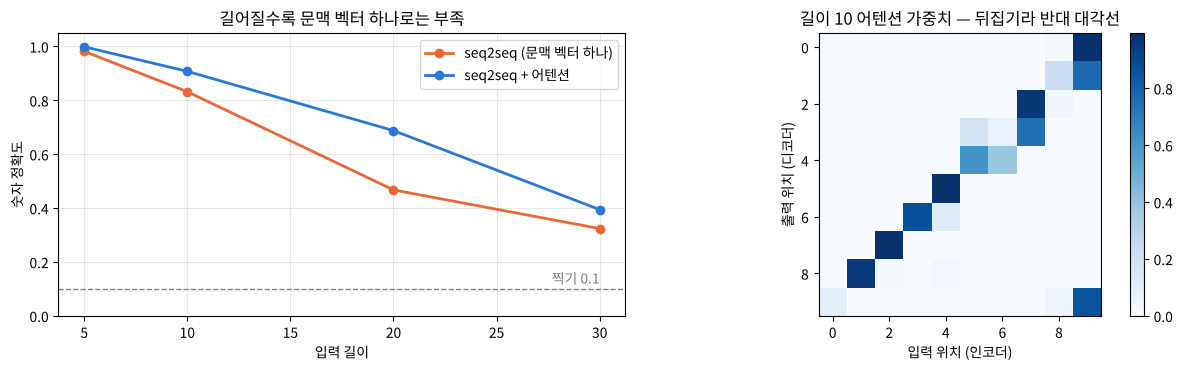

In [9]:
Ls = [5, 10, 20, 30]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(Ls, [results[(L, False)] for L in Ls], 'o-', color='#eb6834', lw=2, label='seq2seq (문맥 벡터 하나)')
axes[0].plot(Ls, [results[(L, True)] for L in Ls], 'o-', color='#2a78d6', lw=2, label='seq2seq + 어텐션')
axes[0].axhline(0.1, color='gray', ls='--', lw=1); axes[0].text(30, 0.12, '찍기 0.1', ha='right', color='gray')
axes[0].set_xlabel('입력 길이'); axes[0].set_ylabel('숫자 정확도'); axes[0].set_ylim(0, 1.05)
axes[0].legend(); axes[0].grid(alpha=0.3); axes[0].set_title('길어질수록 문맥 벡터 하나로는 부족')
im = axes[1].imshow(att_maps[10].numpy(), cmap='Blues')
axes[1].set_xlabel('입력 위치 (인코더)'); axes[1].set_ylabel('출력 위치 (디코더)')
axes[1].set_title('길이 10 어텐션 가중치 — 뒤집기라 반대 대각선')
plt.colorbar(im, ax=axes[1], fraction=0.046); plt.tight_layout(); plt.show()

- 문맥 벡터 하나(64칸)만 넘기면 길이가 길어질수록 정확도가 무너진다 — 교재 p.87 '**고정된 크기**의 문맥 벡터' 가 병목이다.
- 디코더가 매 단계 인코더의 모든 시점을 다시 보게 하면(어텐션) 같은 크기 · 같은 학습량으로 더 잘 버틴다 — 길이 10~20 에서 차이가 크고, 길이 30 은 둘 다 1,500번 학습으로는 부족하다(더 오래 학습해야 한다).
- 오른쪽 가중치 그림은 대체로 **반대 대각선** — 출력 1번째 숫자는 입력 마지막 숫자를 본다. 뒤집기 규칙을 스스로 찾았다. 한 칸씩 어긋난 줄은 '지금 낼 숫자' 대신 '방금 낸 숫자의 자리' 를 보는 것으로, 그 옆 칸이 다음 숫자라는 계산은 디코더 GRU 가 이어서 하는 것으로 보인다(어텐션을 이전 은닉 상태로 계산하므로 — 역할 분담은 학습이 정한다).
- Transformer(교재 p.88~89)는 여기서 한 걸음 더 나가 **RNN 을 아예 빼고** 어텐션만으로 인코더 · 디코더를 만든다.

> **📝 고친 부분 (교재 p.87 그림)** 본문은 '두 개의 순환 신경망' 인데 그림의 칸은 **LSTM** — LSTM 도 순환 신경망의 한 종류라 맞는 말이다. 디코더 입력이 `<sos> je suis étudiant` 처럼 **정답을 한 칸 밀어 넣은 것**은 학습 때의 **교사 강요(teacher forcing)** 이고, 실제 번역(추론) 때는 자기가 방금 낸 단어를 다음 입력으로 쓴다 — 위 `train_eval` 의 학습 · 평가 부분.

## 4. 교재 p.85 RNN 분류 코드 — `Sigmoid` 를 넣었다면 손실은 `BCELoss`

In [10]:
class RNNClassifier(nn.Module):                          # 교재 p.85 그대로
    def __init__(self, vocab_size=10000, embed_dim=32, hidden_dim=16, output_dim=1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, output_dim)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        embedded = self.embedding(x)
        output, hidden = self.rnn(embedded)
        out = self.fc(hidden.squeeze(0))
        return self.sigmoid(out)

m = RNNClassifier()
xin = torch.randint(1, 10000, (4, 470))
y = torch.tensor([[1.], [0.], [1.], [0.]])
p = m(xin)                                                            # 확률 (sigmoid 통과)
logit = m.fc(m.rnn(m.embedding(xin))[1].squeeze(0))                   # sigmoid 전 값
print('출력 모양 :', tuple(p.shape), '| 확률 :', p.squeeze().detach().numpy().round(3))
print('BCELoss(확률)              :', round(nn.BCELoss()(p, y).item(), 5))
print('BCEWithLogitsLoss(logit) ✓ :', round(nn.BCEWithLogitsLoss()(logit, y).item(), 5), '← 위와 같은 값')
print('BCEWithLogitsLoss(확률)  ✗ :', round(nn.BCEWithLogitsLoss()(p, y).item(), 5), '← sigmoid 를 두 번 거쳐 틀린 값')

출력 모양 : (4, 1) | 확률 : [0.508 0.644 0.627 0.582]
BCELoss(확률)              : 0.7619
BCEWithLogitsLoss(logit) ✓ : 0.7619 ← 위와 같은 값
BCEWithLogitsLoss(확률)  ✗ : 0.74768 ← sigmoid 를 두 번 거쳐 틀린 값


교재 코드는 출력에 `Sigmoid` 를 두므로 손실은 **`BCELoss`** 와 짝을 맞춰야 한다. Day 042 노트처럼 `Sigmoid` 없이 logit 을 내보내면 **`BCEWithLogitsLoss`**(더 안정적). 둘을 섞으면(확률을 `BCEWithLogitsLoss` 에) 손실이 틀린 값이 되어 학습이 잘 안 된다.

## 5. Transformer 구조 (교재 p.88~89)

| 블록 | 하는 일 |
|---|---|
| 입력 임베딩 + **위치 정보** | 단어 벡터에 순서 정보를 더한다 (RNN 이 아니라 순서를 모르므로) |
| 인코더 층 × N | **Multi-Head self-Attention** → Feed Forward (각각 잔차 연결 + 층 정규화) |
| 디코더 층 × N | **Masked** Multi-Head self-Attention(뒤 단어 못 보게) → 인코더 출력을 key · value 로 쓰는 Attention → Feed Forward |
| 출력 | Linear + softmax → 다음 단어 확률 |

In [11]:
layer = nn.TransformerEncoderLayer(d_model=512, nhead=8, dim_feedforward=2048, batch_first=True)
print(layer)
x = torch.randn(1, 3, 512)                                  # 'I love you' 3 단어 × 512
print('\n입력', tuple(x.shape), '→ 인코더 층 출력', tuple(layer(x).shape), '(모양 그대로, 내용은 문맥 반영)')
print('인코더 층 1개 가중치 :', f'{sum(p.numel() for p in layer.parameters()):,}', '개')

TransformerEncoderLayer(
  (self_attn): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=512, out_features=512, bias=True)
  )
  (linear1): Linear(in_features=512, out_features=2048, bias=True)
  (dropout): Dropout(p=0.1, inplace=False)
  (linear2): Linear(in_features=2048, out_features=512, bias=True)
  (norm1): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
  (norm2): LayerNorm((512,), eps=1e-05, elementwise_affine=True, bias=True)
  (dropout1): Dropout(p=0.1, inplace=False)
  (dropout2): Dropout(p=0.1, inplace=False)
)

입력 (1, 3, 512) → 인코더 층 출력 (1, 3, 512) (모양 그대로, 내용은 문맥 반영)
인코더 층 1개 가중치 : 3,152,384 개


> **📝 고친 부분 (교재 p.88 · p.89)**
> - 논문 제목 `Attention is all you need` → **Attention Is All You Need** (Vaswani 외, 2017 · Google Brain / Google Research)
> - p.89 그림에는 각 블록 뒤의 **Add & Norm**(잔차 연결 + 층 정규화)이 빠져 있다 — 위 `TransformerEncoderLayer` 출력의 `norm1` · `norm2`. 그림의 `Feed Forwrad` → **Forward**
> - 그림 속 `Multi HEAD Attention` 은 다음 노트의 self-attention 을 **여러 개(head) 나란히** 한 것 — 512 를 8개 head 가 64씩 나눠 계산

## 정리

| 문제 (RNN · seq2seq) | 원인 | Transformer 의 해결 |
|---|---|---|
| 기울기 소멸 · 폭주 | 시점마다 tanh′ × $W_h$ 를 곱함 | 모든 단어가 어텐션으로 **직접 연결** (거리 1) |
| 장기 의존성 | 앞 정보가 수십 칸을 지나며 희석 | 같은 이유 |
| 병렬 처리 | $h_t$ 가 $h_{t-1}$ 을 기다림 | 문장 전체를 행렬 곱 한 번 |
| 문맥 벡터 병목 | 문장 전체를 고정 크기 벡터 하나로 | 단어마다 문맥 반영 벡터 (다음 노트) |